In [1]:
# FINAL MODEL CHECKPOINT AUDIT

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT_ROOT = Path(
    '/content/drive/MyDrive/Insight_Hunters_Project'
)

CHECKPOINT_ROOT = PROJECT_ROOT / '03_Model_Checkpoints'

MODEL_PATHS = {
    'VGG16': CHECKPOINT_ROOT / 'VGG16' / 'VGG16_stage2_best.keras',

    'ResNet50': CHECKPOINT_ROOT / 'ResNet50' / 'ResNet50_stage2_best.keras',

    'DenseNet121': CHECKPOINT_ROOT / 'DenseNet121_Standardized' / 'stage2_best.keras',

    'EfficientNetB0': CHECKPOINT_ROOT / 'EfficientNetB0_Final' / 'efficientnetb0_FINAL_best.keras'
}

print("=" * 60)
print("INSIGHT HUNTERS (FINAL MODEL CHECKPOINT AUDIT)")
print("=" * 60)

all_found = True

for model_name, model_path in MODEL_PATHS.items():

    if model_path.is_file():
        size_mb = model_path.stat().st_size / (1024 ** 2)

        print(f"\n✅ {model_name}")
        print(f"   Checkpoint: {model_path.name}")
        print(f"   File size: {size_mb:.2f} MB")

    else:
        print(f"\n❌ {model_name}")
        print(f"   CHECKPOINT NOT FOUND: {model_path}")
        all_found = False

print("\n" + "=" * 60)

if all_found:
    print("✅ ALL FOUR CHECKPOINT FILES FOUND")
else:
    print("⚠️ AUDIT INCOMPLETE — CHECK MISSING FILES")

Mounted at /content/drive
INSIGHT HUNTERS (FINAL MODEL CHECKPOINT AUDIT)

✅ VGG16
   Checkpoint: VGG16_stage2_best.keras
   File size: 110.26 MB

✅ ResNet50
   Checkpoint: ResNet50_stage2_best.keras
   File size: 204.75 MB

✅ DenseNet121
   Checkpoint: stage2_best.keras
   File size: 46.09 MB

✅ EfficientNetB0
   Checkpoint: efficientnetb0_FINAL_best.keras
   File size: 24.82 MB

✅ ALL FOUR CHECKPOINT FILES FOUND


In [2]:
# MODEL LOADING & ARCHITECTURE VERIFICATION


import tensorflow as tf
import gc

print("=" * 65)
print("INSIGHT HUNTERS (MODEL ARCHITECTURE AUDIT)")
print("=" * 65)

print(f"\nTensorFlow version: {tf.__version__}")

audit_results = {}

for model_name, model_path in MODEL_PATHS.items():

    print(f"\n{'=' * 55}")
    print(f"Checking: {model_name}")
    print(f"{'=' * 55}")

    try:
        # Loading the saved model without recompiling
        model = tf.keras.models.load_model(
            str(model_path),
            compile=False
        )

        input_shape = model.input_shape
        output_shape = model.output_shape
        total_params = model.count_params()

        # Expected binary classification configuration
        input_valid = tuple(input_shape[1:]) == (224, 224, 3)
        output_valid = tuple(output_shape[1:]) == (1,)

        audit_results[model_name] = {
            "loaded": True,
            "input_shape": str(input_shape),
            "output_shape": str(output_shape),
            "parameters": total_params,
            "input_valid": input_valid,
            "output_valid": output_valid
        }

        print("✅ Model loaded successfully")
        print(f"Input shape: {input_shape}")
        print(f"Output shape: {output_shape}")
        print(f"Total parameters: {total_params:,}")

        if input_valid and output_valid:
            print("✅ Input/output configuration verified")
        else:
            print("⚠️ Unexpected input/output configuration")

        del model
        tf.keras.backend.clear_session()
        gc.collect()

    except Exception as e:

        audit_results[model_name] = {
            "loaded": False,
            "error": str(e)
        }

        print(f"❌ Loading failed: {e}")

print("\n" + "=" * 65)

if all(
    result.get("loaded", False)
    and result.get("input_valid", False)
    and result.get("output_valid", False)
    for result in audit_results.values()
):
    print("✅ ALL FOUR MODELS PASSED THE ARCHITECTURE AUDIT")
else:
    print("⚠️ ARCHITECTURE AUDIT REQUIRES ATTENTION")

INSIGHT HUNTERS (MODEL ARCHITECTURE AUDIT)

TensorFlow version: 2.21.0

Checking: VGG16
✅ Model loaded successfully
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 14,715,201
✅ Input/output configuration verified

Checking: ResNet50
✅ Model loaded successfully
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 23,589,761
✅ Input/output configuration verified

Checking: DenseNet121
✅ Model loaded successfully
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 7,168,833
✅ Input/output configuration verified

Checking: EfficientNetB0
✅ Model loaded successfully
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 4,050,852
✅ Input/output configuration verified

✅ ALL FOUR MODELS PASSED THE ARCHITECTURE AUDIT


In [3]:
# PREDICTION CONFIGURATION AUDIT

import tensorflow as tf
import gc

print("=" * 65)
print("INSIGHT HUNTERS (PREDICTION CONFIGURATION AUDIT)")
print("=" * 65)

for model_name, model_path in MODEL_PATHS.items():

    print(f"\n{'=' * 55}")
    print(f"Checking: {model_name}")
    print(f"{'=' * 55}")

    model = tf.keras.models.load_model(
        str(model_path),
        compile=False
    )

    # Inspecting the final prediction layer
    final_layer = model.layers[-1]

    print(f"Final layer: {final_layer.name}")
    print(f"Layer type: {type(final_layer).__name__}")

    if hasattr(final_layer, "activation"):
        activation = final_layer.activation.__name__
        print(f"Activation: {activation}")

        if activation == "sigmoid":
            print("✅ Sigmoid activation confirmed")
        else:
            print("⚠️ Expected sigmoid activation")

    # Inspecting the top-level preprocessing-related layers
    preprocessing_layers = []

    for layer in model.layers:
        layer_type = type(layer).__name__

        if layer_type in [
            "Rescaling",
            "Normalization",
            "Resizing",
            "RandomRotation",
            "RandomTranslation",
            "RandomZoom",
            "RandomContrast"
        ]:
            preprocessing_layers.append(
                f"{layer.name} ({layer_type})"
            )

    if preprocessing_layers:
        print("Top-level preprocessing/augmentation layers:")
        for layer in preprocessing_layers:
            print(f"  - {layer}")
    else:
        print("No top-level preprocessing layers detected.")

    del model
    tf.keras.backend.clear_session()
    gc.collect()

print("\n" + "=" * 65)
print("PREDICTION CONFIGURATION INSPECTION COMPLETE")

INSIGHT HUNTERS (PREDICTION CONFIGURATION AUDIT)

Checking: VGG16
Final layer: tb_prediction
Layer type: Dense
Activation: sigmoid
✅ Sigmoid activation confirmed
No top-level preprocessing layers detected.

Checking: ResNet50
Final layer: tb_prediction
Layer type: Dense
Activation: sigmoid
✅ Sigmoid activation confirmed
No top-level preprocessing layers detected.

Checking: DenseNet121
Final layer: tb_prediction
Layer type: Dense
Activation: sigmoid
✅ Sigmoid activation confirmed
No top-level preprocessing layers detected.

Checking: EfficientNetB0
Final layer: tb_prediction
Layer type: Dense
Activation: sigmoid
✅ Sigmoid activation confirmed
No top-level preprocessing layers detected.

PREDICTION CONFIGURATION INSPECTION COMPLETE


In [4]:
# PREPROCESSING LAYER INSPECTION

import tensorflow as tf
import gc

print("=" * 65)
print("INSIGHT HUNTERS (PREPROCESSING INSPECTION)")
print("=" * 65)

for model_name, model_path in MODEL_PATHS.items():

    print(f"\n{'=' * 55}")
    print(f"MODEL: {model_name}")
    print(f"{'=' * 55}")

    model = tf.keras.models.load_model(
        str(model_path),
        compile=False
    )

    print("\nFirst 12 top-level layers:")

    for layer in model.layers[:12]:
        print(
            f"{layer.name:35s} "
            f"{type(layer).__name__}"
        )

    print("\nNested model layers:")

    for layer in model.layers:
        if isinstance(layer, tf.keras.Model):
            print(
                f"  {layer.name}: "
                f"{len(layer.layers)} internal layers"
            )

    del model
    tf.keras.backend.clear_session()
    gc.collect()

print("\n" + "=" * 65)
print("PREPROCESSING INSPECTION COMPLETE")

INSIGHT HUNTERS (PREPROCESSING INSPECTION)

MODEL: VGG16

First 12 top-level layers:
input_image                         InputLayer
shared_data_augmentation            Sequential
vgg16                               Functional
global_average_pooling              GlobalAveragePooling2D
dropout                             Dropout
tb_prediction                       Dense

Nested model layers:
  shared_data_augmentation: 4 internal layers
  vgg16: 19 internal layers

MODEL: ResNet50

First 12 top-level layers:
input_image                         InputLayer
shared_data_augmentation            Sequential
resnet50                            Functional
global_average_pooling              GlobalAveragePooling2D
dropout                             Dropout
tb_prediction                       Dense

Nested model layers:
  shared_data_augmentation: 4 internal layers
  resnet50: 175 internal layers

MODEL: DenseNet121

First 12 top-level layers:
input_image                         InputLayer
standar

In [5]:
# LOADING & VERIFYING THE LOCKED TEST DATASET

import tensorflow as tf
from pathlib import Path

TEST_DIR = PROJECT_ROOT / "02_Data_Splits" / "test"

CLASS_NAMES = ["tb_negative", "tb_positive"]

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

assert TEST_DIR.is_dir(), f"Test directory not found: {TEST_DIR}"

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    color_mode="rgb"
)

# Counting the images in each class
class_counts = {
    class_name: len([
        p for p in (TEST_DIR / class_name).iterdir()
        if p.is_file()
    ])
    for class_name in CLASS_NAMES
}

print("\n" + "=" * 60)
print("INSIGHT HUNTERS (FINAL TEST DATASET VERIFICATION)")
print("=" * 60)

print(f"Test directory: {TEST_DIR}")
print(f"Total test images: {sum(class_counts.values())}")
print(f"TB Negative (0): {class_counts['tb_negative']}")
print(f"TB Positive (1): {class_counts['tb_positive']}")
print(f"Class mapping: {dict(enumerate(CLASS_NAMES))}")
print(f"Image size: {IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print("Shuffle: False")

# Confirming the expected test-set composition
assert sum(class_counts.values()) == 120, "Unexpected test image count!"
assert class_counts["tb_negative"] == 61, "Unexpected negative count!"
assert class_counts["tb_positive"] == 59, "Unexpected positive count!"

# Verifying the image tensors
for images, labels in test_ds.take(1):
    print(f"\nImage batch shape: {images.shape}")
    print(f"Label batch shape: {labels.shape}")
    print(f"Pixel range: {tf.reduce_min(images).numpy():.1f} "
          f"to {tf.reduce_max(images).numpy():.1f}")

print("\n✅ TEST DATASET VERIFICATION PASSED")

Found 120 files belonging to 2 classes.

INSIGHT HUNTERS (FINAL TEST DATASET VERIFICATION)
Test directory: /content/drive/MyDrive/Insight_Hunters_Project/02_Data_Splits/test
Total test images: 120
TB Negative (0): 61
TB Positive (1): 59
Class mapping: {0: 'tb_negative', 1: 'tb_positive'}
Image size: (224, 224)
Batch size: 32
Shuffle: False

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 1)
Pixel range: 0.0 to 255.0

✅ TEST DATASET VERIFICATION PASSED


In [6]:
# VGG16 FINAL TEST EVALUATION

import tensorflow as tf
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

# Loading the locked VGG16 checkpoint
vgg16_model = tf.keras.models.load_model(
    str(MODEL_PATHS["VGG16"]),
    compile=False
)

# Collecting ground-truth labels
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

# Generating predictions (inference only)
y_prob = vgg16_model.predict(test_ds, verbose=1).ravel()

# Fixed classification threshold
THRESHOLD = 0.5
y_pred = (y_prob >= THRESHOLD).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

# Calculating the metrics
results_vgg16 = {
    "Model": "VGG16",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Sensitivity": recall_score(y_true, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "F1-score": f1_score(y_true, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_true, y_prob)
}

print("\n" + "=" * 60)
print("INSIGHT HUNTERS (VGG16 FINAL TEST RESULTS)")
print("=" * 60)

for metric, value in results_vgg16.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

print("\nConfusion Matrix:")
print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:  {tp}")

print("\n✅ VGG16 FINAL TEST EVALUATION COMPLETE")

4/4 ━━━━━━━━━━━━━━━━━━━━ 84s 17s/step

INSIGHT HUNTERS (VGG16 FINAL TEST RESULTS)
Model: VGG16
Accuracy: 0.8333 (83.33%)
Sensitivity: 0.7119 (71.19%)
Specificity: 0.9508 (95.08%)
Precision: 0.9333 (93.33%)
F1-score: 0.8077 (80.77%)
ROC-AUC: 0.9241 (92.41%)

Confusion Matrix:
True Negatives:  58
False Positives: 3
False Negatives: 17
True Positives:  42

✅ VGG16 FINAL TEST EVALUATION COMPLETE


In [7]:
# RESNET50 FINAL TEST EVALUATION

import gc

resnet50_model = tf.keras.models.load_model(
    str(MODEL_PATHS["ResNet50"]),
    compile=False
)

# Generating the predictions
resnet50_prob = resnet50_model.predict(
    test_ds,
    verbose=1
).ravel()

resnet50_pred = (resnet50_prob >= THRESHOLD).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_true,
    resnet50_pred,
    labels=[0, 1]
).ravel()

results_resnet50 = {
    "Model": "ResNet50",
    "Accuracy": accuracy_score(y_true, resnet50_pred),
    "Sensitivity": recall_score(y_true, resnet50_pred, zero_division=0),
    "Specificity": tn / (tn + fp),
    "Precision": precision_score(y_true, resnet50_pred, zero_division=0),
    "F1-score": f1_score(y_true, resnet50_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_true, resnet50_prob)
}

print("\n" + "=" * 60)
print("INSIGHT HUNTERS (RESNET50 FINAL TEST RESULTS)")
print("=" * 60)

for metric, value in results_resnet50.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

print("\nConfusion Matrix:")
print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:  {tp}")

print("\n✅ RESNET50 FINAL TEST EVALUATION COMPLETE")

# Releasing the model memory
del resnet50_model
tf.keras.backend.clear_session()
gc.collect()

4/4 ━━━━━━━━━━━━━━━━━━━━ 43s 6s/step

INSIGHT HUNTERS (RESNET50 FINAL TEST RESULTS)
Model: ResNet50
Accuracy: 0.8750 (87.50%)
Sensitivity: 0.7966 (79.66%)
Specificity: 0.9508 (95.08%)
Precision: 0.9400 (94.00%)
F1-score: 0.8624 (86.24%)
ROC-AUC: 0.9364 (93.64%)

Confusion Matrix:
True Negatives:  58
False Positives: 3
False Negatives: 12
True Positives:  47

✅ RESNET50 FINAL TEST EVALUATION COMPLETE


0

In [8]:
# DENSENET121 FINAL TEST EVALUATION

import gc

densenet121_model = tf.keras.models.load_model(
    str(MODEL_PATHS["DenseNet121"]),
    compile=False
)

# Generating the predictions
densenet121_prob = densenet121_model.predict(
    test_ds,
    verbose=1
).ravel()

densenet121_pred = (
    densenet121_prob >= THRESHOLD
).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_true,
    densenet121_pred,
    labels=[0, 1]
).ravel()

results_densenet121 = {
    "Model": "DenseNet121",
    "Accuracy": accuracy_score(y_true, densenet121_pred),
    "Sensitivity": recall_score(
        y_true, densenet121_pred, zero_division=0
    ),
    "Specificity": tn / (tn + fp),
    "Precision": precision_score(
        y_true, densenet121_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_true, densenet121_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_true, densenet121_prob
    )
}

print("\n" + "=" * 60)
print("INSIGHT HUNTERS (DENSENET121 FINAL TEST RESULTS)")
print("=" * 60)

for metric, value in results_densenet121.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

print("\nConfusion Matrix:")
print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:  {tp}")

print("\n✅ DENSENET121 FINAL TEST EVALUATION COMPLETE")

# Releasing the model memory
del densenet121_model
tf.keras.backend.clear_session()
gc.collect()

3/4 ━━━━━━━━━━━━━━━━━━━━ 4s 5s/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 42s 6s/step

INSIGHT HUNTERS — DENSENET121 FINAL TEST RESULTS
Model: DenseNet121
Accuracy: 0.8250 (82.50%)
Sensitivity: 0.7458 (74.58%)
Specificity: 0.9016 (90.16%)
Precision: 0.8800 (88.00%)
F1-score: 0.8073 (80.73%)
ROC-AUC: 0.9228 (92.28%)

Confusion Matrix:
True Negatives:  55
False Positives: 6
False Negatives: 15
True Positives:  44

✅ DENSENET121 FINAL TEST EVALUATION COMPLETE


0

In [9]:
# EFFICIENTNET-B0 FINAL TEST EVALUATION

import gc

efficientnet_model = tf.keras.models.load_model(
    str(MODEL_PATHS["EfficientNetB0"]),
    compile=False
)

# Generating the predictions
efficientnet_prob = efficientnet_model.predict(
    test_ds,
    verbose=1
).ravel()

efficientnet_pred = (
    efficientnet_prob >= THRESHOLD
).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_true,
    efficientnet_pred,
    labels=[0, 1]
).ravel()

results_efficientnet = {
    "Model": "EfficientNetB0",
    "Accuracy": accuracy_score(y_true, efficientnet_pred),
    "Sensitivity": recall_score(
        y_true, efficientnet_pred, zero_division=0
    ),
    "Specificity": tn / (tn + fp),
    "Precision": precision_score(
        y_true, efficientnet_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_true, efficientnet_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_true, efficientnet_prob
    )
}

print("\n" + "=" * 60)
print("INSIGHT HUNTERS (EFFICIENTNET-B0 FINAL TEST RESULTS)")
print("=" * 60)

for metric, value in results_efficientnet.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

print("\nConfusion Matrix:")
print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:  {tp}")

print("\n✅ EFFICIENTNET-B0 FINAL TEST EVALUATION COMPLETE")

# Releasing the model memory
del efficientnet_model
tf.keras.backend.clear_session()
gc.collect()

4/4 ━━━━━━━━━━━━━━━━━━━━ 34s 4s/step

INSIGHT HUNTERS (EFFICIENTNET-B0 FINAL TEST RESULTS)
Model: EfficientNetB0
Accuracy: 0.7417 (74.17%)
Sensitivity: 0.7966 (79.66%)
Specificity: 0.6885 (68.85%)
Precision: 0.7121 (71.21%)
F1-score: 0.7520 (75.20%)
ROC-AUC: 0.8630 (86.30%)

Confusion Matrix:
True Negatives:  42
False Positives: 19
False Negatives: 12
True Positives:  47

✅ EFFICIENTNET-B0 FINAL TEST EVALUATION COMPLETE


0

In [13]:
# CONSOLIDATED MODEL COMPARISON

import pandas as pd

all_results = [
    results_vgg16,
    results_resnet50,
    results_densenet121,
    results_efficientnet
]

comparison_df = pd.DataFrame(all_results)

comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("INSIGHT HUNTERS (FINAL MODEL COMPARISON)")
print("=" * 80)

display(
    comparison_df.style.format({
        "Accuracy": "{:.2%}",
        "Sensitivity": "{:.2%}",
        "Specificity": "{:.2%}",
        "Precision": "{:.2%}",
        "F1-score": "{:.2%}",
        "ROC-AUC": "{:.2%}"
    })
)

print("\n✅ FOUR-MODEL COMPARISON TABLE GENERATED")

INSIGHT HUNTERS (FINAL MODEL COMPARISON)


,Model,Accuracy,Sensitivity,Specificity,Precision,F1-score,ROC-AUC
0,ResNet50,87.50%,79.66%,95.08%,94.00%,86.24%,93.64%
1,VGG16,83.33%,71.19%,95.08%,93.33%,80.77%,92.41%
2,DenseNet121,82.50%,74.58%,90.16%,88.00%,80.73%,92.28%
3,EfficientNetB0,74.17%,79.66%,68.85%,71.21%,75.20%,86.30%



✅ FOUR-MODEL COMPARISON TABLE GENERATED


In [14]:
# SAVING THE FINAL MODEL COMPARISON RESULTS

from pathlib import Path

# Creating a dedicated folder for final evaluation results
RESULTS_DIR = PROJECT_ROOT / "04_Results" / "Final_Model_Evaluation"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Saving the comparison table
comparison_path = RESULTS_DIR / "four_model_test_comparison.csv"

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("=" * 65)
print("INSIGHT HUNTERS (FINAL RESULTS EXPORT)")
print("=" * 65)

print(f"\nResults saved to:\n{comparison_path}")

print("\nModels included:")
for model_name in comparison_df["Model"]:
    print(f"✅ {model_name}")

print("\n✅ FINAL COMPARISON TABLE SAVED SUCCESSFULLY")

INSIGHT HUNTERS (FINAL RESULTS EXPORT)

Results saved to:
/content/drive/MyDrive/Insight_Hunters_Project/04_Results/Final_Model_Evaluation/four_model_test_comparison.csv

Models included:
✅ ResNet50
✅ VGG16
✅ DenseNet121
✅ EfficientNetB0

✅ FINAL COMPARISON TABLE SAVED SUCCESSFULLY


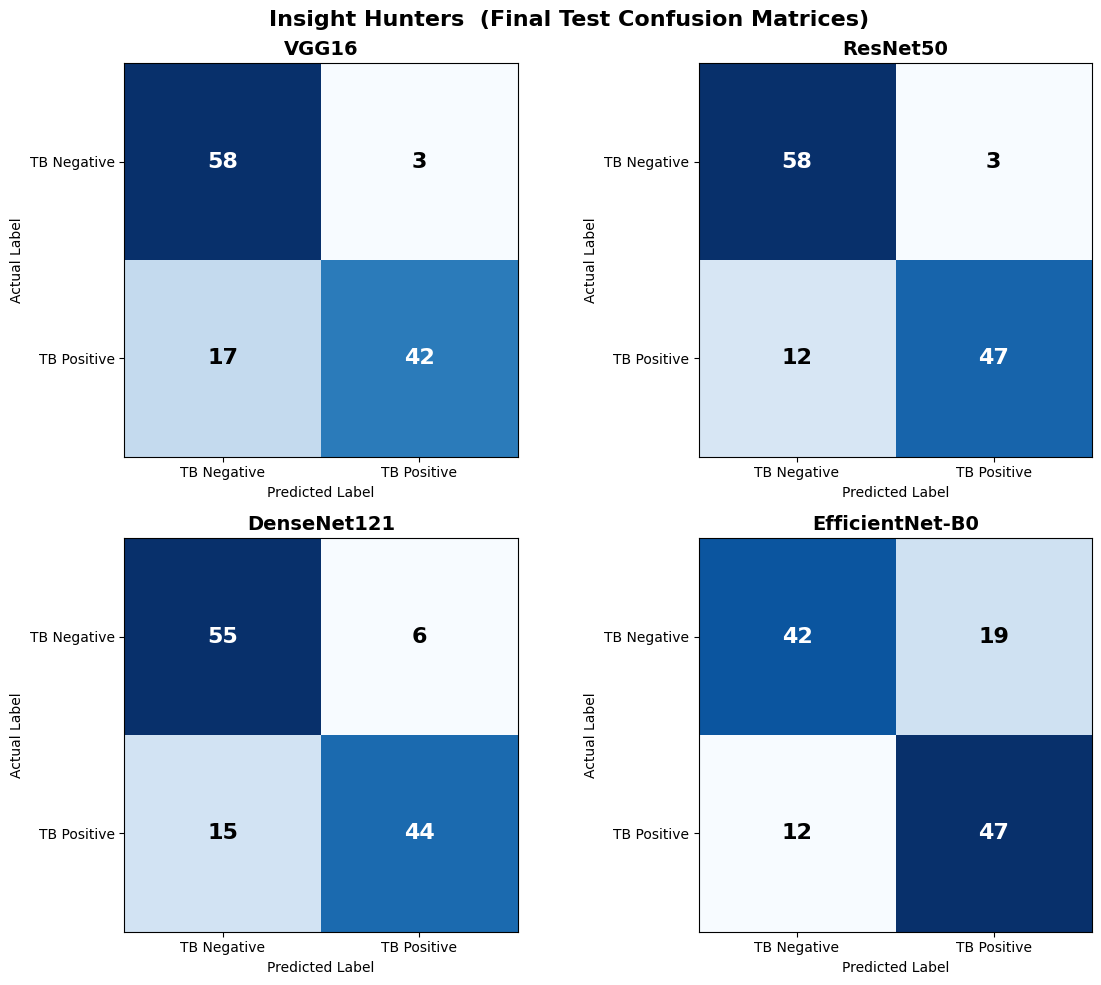


INSIGHT HUNTERS (CONFUSION MATRIX EXPORT)

Saved to:
/content/drive/MyDrive/Insight_Hunters_Project/04_Results/Final_Model_Evaluation/four_model_confusion_matrices.png

✅ ALL FOUR CONFUSION MATRICES GENERATED AND SAVED


In [15]:
# GENERATE FOUR CONFUSION MATRICES

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

# The predictions
model_predictions = {
    "VGG16": y_pred,
    "ResNet50": resnet50_pred,
    "DenseNet121": densenet121_pred,
    "EfficientNet-B0": efficientnet_pred
}

# Generating a 2x2 comparison figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, predictions) in zip(
    axes.flat, model_predictions.items()
):

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    )

    ax.imshow(cm, cmap="Blues")

    ax.set_title(model_name, fontsize=14, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["TB Negative", "TB Positive"])
    ax.set_yticklabels(["TB Negative", "TB Positive"])

    # Displaying the counts inside the matrix
    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color="white" if cm[i, j] > cm.max() / 2 else "black"
            )

plt.suptitle(
    "Insight Hunters  (Final Test Confusion Matrices)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Saving the figure
figure_path = RESULTS_DIR / "four_model_confusion_matrices.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 65)
print("INSIGHT HUNTERS (CONFUSION MATRIX EXPORT)")
print("=" * 65)
print(f"\nSaved to:\n{figure_path}")
print("\n✅ ALL FOUR CONFUSION MATRICES GENERATED AND SAVED")

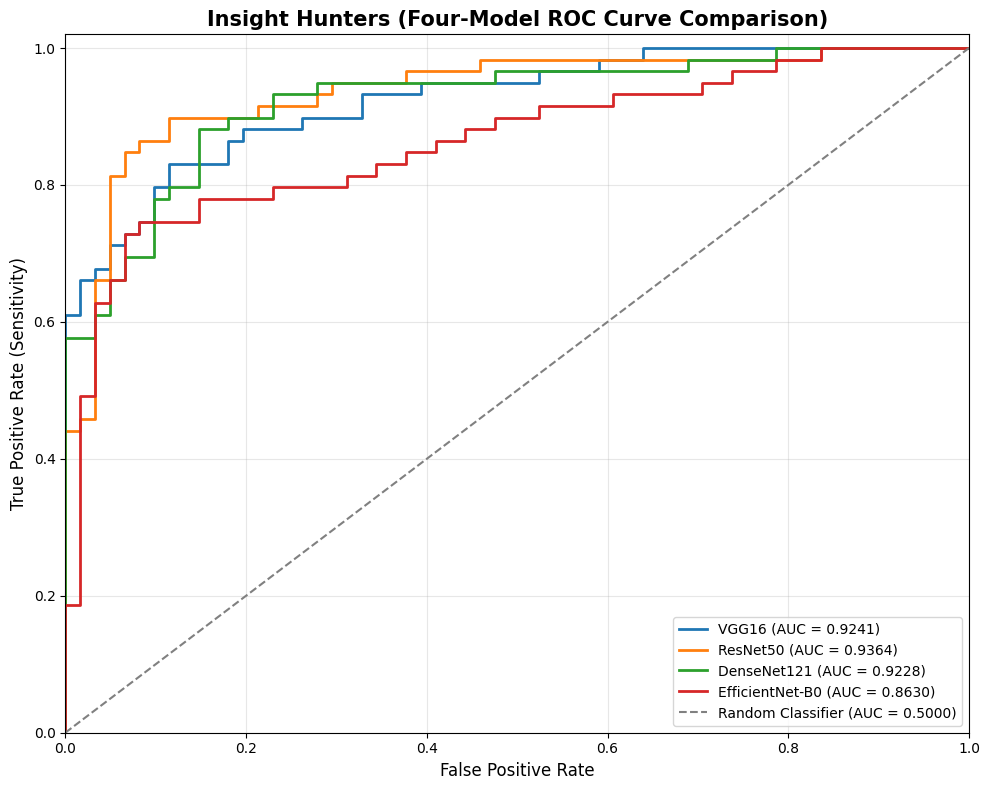


INSIGHT HUNTERS (ROC CURVE EXPORT)

Saved to:
/content/drive/MyDrive/Insight_Hunters_Project/04_Results/Final_Model_Evaluation/four_model_roc_curves.png

✅ FOUR-MODEL ROC CURVES GENERATED AND SAVED


In [16]:
# FOUR-MODEL ROC CURVE COMPARISON


import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# The Probabilities
model_probabilities = {
    "VGG16": y_prob,
    "ResNet50": resnet50_prob,
    "DenseNet121": densenet121_prob,
    "EfficientNet-B0": efficientnet_prob
}

plt.figure(figsize=(10, 8))

for model_name, probabilities in model_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_true,
        probabilities
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.4f})"
    )

# Random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.5000)"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=12)

plt.title(
    "Insight Hunters (Four-Model ROC Curve Comparison)",
    fontsize=15,
    fontweight="bold"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.tight_layout()

# Saving the ROC comparison
roc_path = RESULTS_DIR / "four_model_roc_curves.png"

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 65)
print("INSIGHT HUNTERS (ROC CURVE EXPORT)")
print("=" * 65)

print(f"\nSaved to:\n{roc_path}")

print("\n✅ FOUR-MODEL ROC CURVES GENERATED AND SAVED")

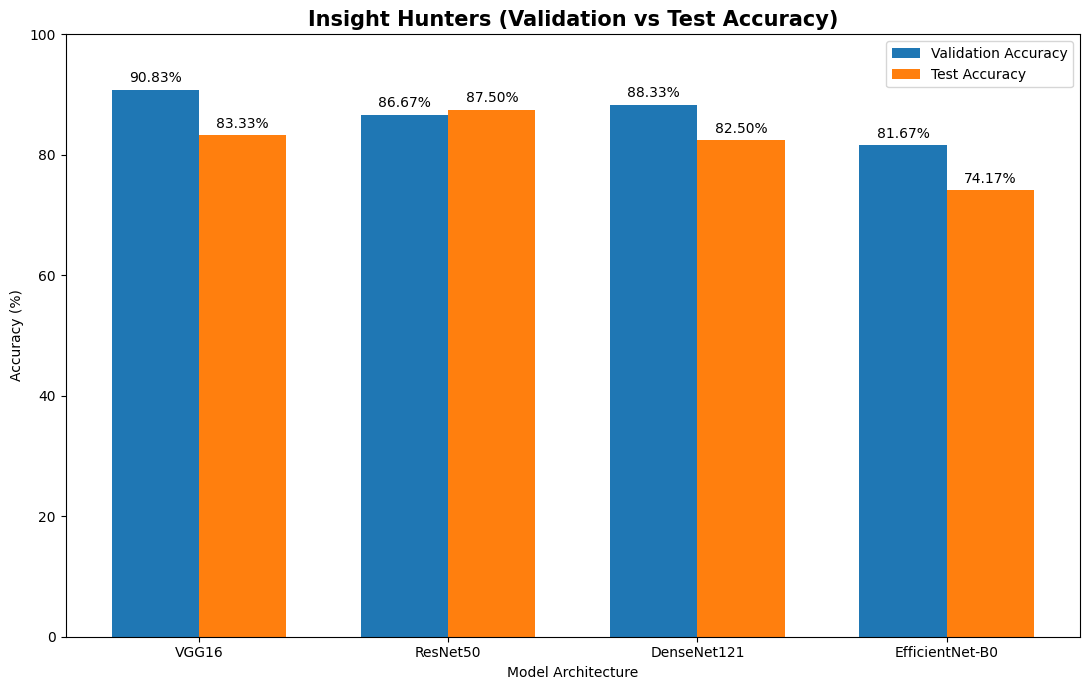


INSIGHT HUNTERS (VALIDATION VS TEST COMPARISON)
VGG16: Validation=90.83% | Test=83.33% | Difference=-7.50 percentage points
ResNet50: Validation=86.67% | Test=87.50% | Difference=+0.83 percentage points
DenseNet121: Validation=88.33% | Test=82.50% | Difference=-5.83 percentage points
EfficientNet-B0: Validation=81.67% | Test=74.17% | Difference=-7.50 percentage points

Saved to:
/content/drive/MyDrive/Insight_Hunters_Project/04_Results/Final_Model_Evaluation/validation_vs_test_accuracy.png

✅ VALIDATION VS TEST ACCURACY COMPARISON COMPLETE


In [17]:
# VALIDATION VS TEST ACCURACY COMPARISON

import matplotlib.pyplot as plt
import numpy as np

model_names = [
    "VGG16",
    "ResNet50",
    "DenseNet121",
    "EfficientNet-B0"
]

# Accuracy at the selected validation checkpoint
validation_accuracy = np.array([
    90.83,
    86.67,
    88.33,
    81.67
])

# Final held-out test accuracy
test_accuracy = np.array([
    83.33,
    87.50,
    82.50,
    74.17
])

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 7))

bars1 = ax.bar(
    x - width / 2,
    validation_accuracy,
    width,
    label="Validation Accuracy"
)

bars2 = ax.bar(
    x + width / 2,
    test_accuracy,
    width,
    label="Test Accuracy"
)

ax.set_xlabel("Model Architecture")
ax.set_ylabel("Accuracy (%)")

ax.set_title(
    "Insight Hunters (Validation vs Test Accuracy)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xticks(x)
ax.set_xticklabels(model_names)

ax.set_ylim(0, 100)
ax.legend()

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()

# Saving the figure
comparison_path = (
    RESULTS_DIR / "validation_vs_test_accuracy.png"
)

plt.savefig(
    comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 65)
print("INSIGHT HUNTERS (VALIDATION VS TEST COMPARISON)")
print("=" * 65)

for model, val_acc, test_acc in zip(
    model_names,
    validation_accuracy,
    test_accuracy
):
    gap = test_acc - val_acc

    print(
        f"{model}: "
        f"Validation={val_acc:.2f}% | "
        f"Test={test_acc:.2f}% | "
        f"Difference={gap:+.2f} percentage points"
    )

print(f"\nSaved to:\n{comparison_path}")

print("\n✅ VALIDATION VS TEST ACCURACY COMPARISON COMPLETE")

INSIGHT HUNTERS  (MODEL COMPLEXITY COMPARISON)


,Model,Parameters,Checkpoint Size (MB),Parameters (Millions)
0,VGG16,14715201,110.26,14.715201
1,ResNet50,23589761,204.75,23.589761
2,DenseNet121,7168833,46.09,7.168833
3,EfficientNet-B0,4050852,24.82,4.050852


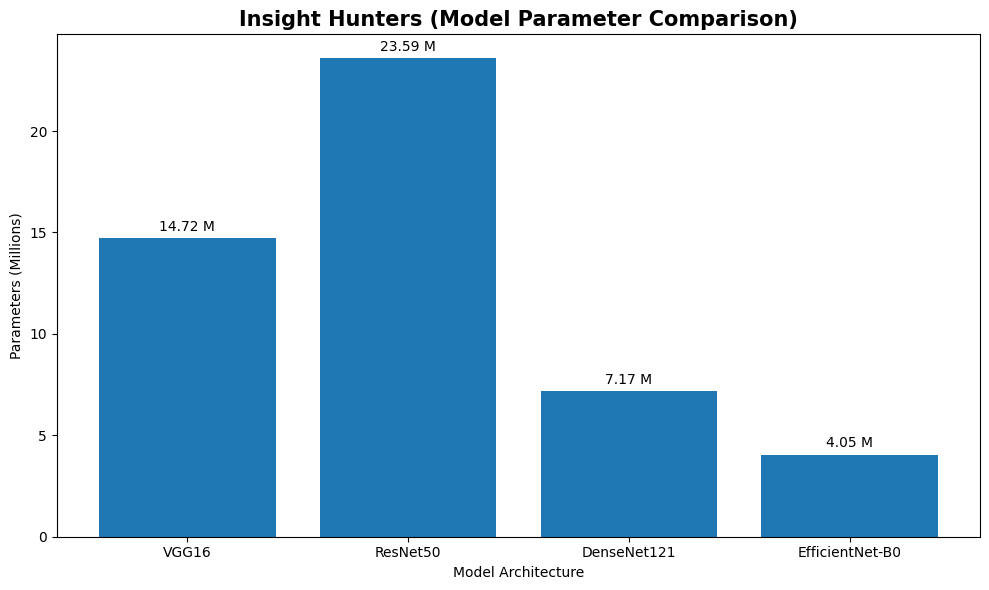


CSV saved to:
/content/drive/MyDrive/Insight_Hunters_Project/04_Results/Final_Model_Evaluation/model_complexity_comparison.csv

Graph saved to:
/content/drive/MyDrive/Insight_Hunters_Project/04_Results/Final_Model_Evaluation/model_parameter_comparison.png

✅ MODEL COMPLEXITY COMPARISON COMPLETE


In [18]:
# MODEL COMPLEXITY COMPARISON


import pandas as pd
import matplotlib.pyplot as plt

complexity_data = {
    "Model": [
        "VGG16",
        "ResNet50",
        "DenseNet121",
        "EfficientNet-B0"
    ],
    "Parameters": [
        14715201,
        23589761,
        7168833,
        4050852
    ],
    "Checkpoint Size (MB)": [
        110.26,
        204.75,
        46.09,
        24.82
    ]
}

complexity_df = pd.DataFrame(complexity_data)

complexity_df["Parameters (Millions)"] = (
    complexity_df["Parameters"] / 1_000_000
)

print("=" * 65)
print("INSIGHT HUNTERS  (MODEL COMPLEXITY COMPARISON)")
print("=" * 65)

display(complexity_df)

# Plot parameter counts
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    complexity_df["Model"],
    complexity_df["Parameters (Millions)"]
)

ax.set_xlabel("Model Architecture")
ax.set_ylabel("Parameters (Millions)")
ax.set_title(
    "Insight Hunters (Model Parameter Comparison)",
    fontsize=15,
    fontweight="bold"
)

ax.bar_label(bars, fmt="%.2f M", padding=3)

plt.tight_layout()

# Saving the outputs
complexity_csv = RESULTS_DIR / "model_complexity_comparison.csv"
complexity_png = RESULTS_DIR / "model_parameter_comparison.png"

complexity_df.to_csv(complexity_csv, index=False)

plt.savefig(
    complexity_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nCSV saved to:\n{complexity_csv}")
print(f"\nGraph saved to:\n{complexity_png}")

print("\n✅ MODEL COMPLEXITY COMPARISON COMPLETE")

,Model,Stage 1 (min),Stage 2 (min),Total (min)
0,VGG16,34.20,16.40,50.60
1,ResNet50,32.11,20.84,52.95
2,DenseNet121,37.44,20.41,57.85
3,EfficientNet-B0,37.80,21.60,59.40


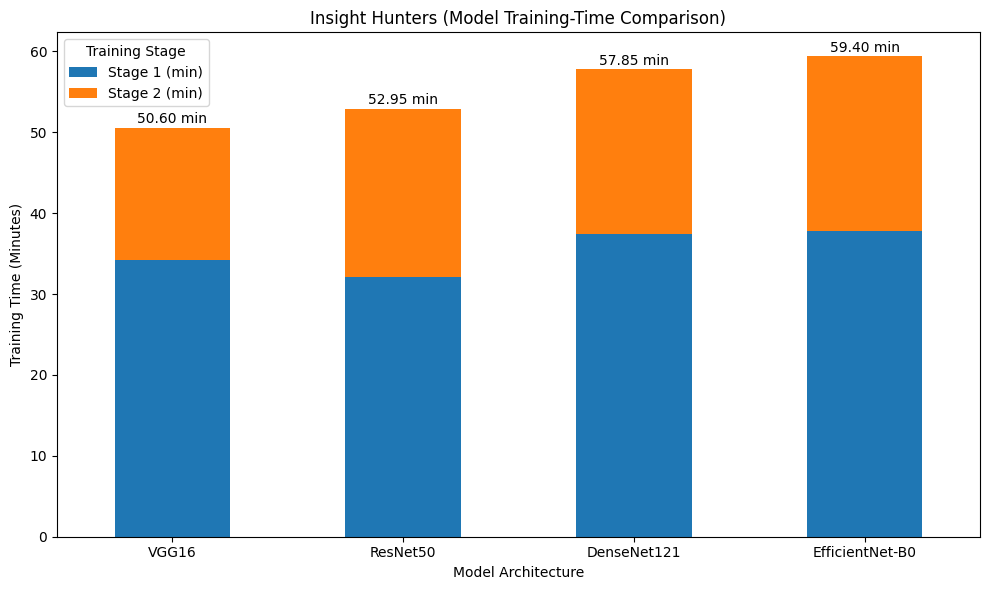


Training-time CSV saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/Final_Model_Evaluation/model_training_times.csv
Training-time graph saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/Final_Model_Evaluation/model_training_time_comparison.png

✅ TRAINING-TIME COMPARISON COMPLETE


In [19]:
# TRAINING-TIME COMPARISON

import pandas as pd
import matplotlib.pyplot as plt

training_time_df = pd.DataFrame({
    "Model": [
        "VGG16",
        "ResNet50",
        "DenseNet121",
        "EfficientNet-B0"
    ],
    "Stage 1 (min)": [
        34.20, 32.11, 37.44, 37.80
    ],
    "Stage 2 (min)": [
        16.40, 20.84, 20.41, 21.60
    ]
})

training_time_df["Total (min)"] = (
    training_time_df["Stage 1 (min)"]
    + training_time_df["Stage 2 (min)"]
)

display(training_time_df)

# Generating a stacked bar chart
ax = training_time_df.plot(
    x="Model",
    y=["Stage 1 (min)", "Stage 2 (min)"],
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    rot=0
)

ax.set_title(
    "Insight Hunters (Model Training-Time Comparison)"
)
ax.set_xlabel("Model Architecture")
ax.set_ylabel("Training Time (Minutes)")
ax.legend(title="Training Stage")

for i, total in enumerate(training_time_df["Total (min)"]):
    ax.text(
        i,
        total + 0.5,
        f"{total:.2f} min",
        ha="center"
    )

plt.tight_layout()

# Save results
training_csv = RESULTS_DIR / "model_training_times.csv"
training_png = RESULTS_DIR / "model_training_time_comparison.png"

training_time_df.to_csv(training_csv, index=False)

plt.savefig(
    training_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nTraining-time CSV saved to:", training_csv)
print("Training-time graph saved to:", training_png)

print("\n✅ TRAINING-TIME COMPARISON COMPLETE")

In [20]:
# FORMAL MODEL SELECTION RECORD

from pathlib import Path
import json

selection_record = {
    "project": "Insight Hunters - Tuberculosis Classification",
    "selected_model": "ResNet50",
    "checkpoint": str(MODEL_PATHS["ResNet50"]),
    "selection_basis": (
        "Comparative evaluation of four pretrained CNN "
        "architectures using the same 120-image held-out "
        "test set and a fixed classification threshold of 0.5."
    ),
    "test_results": {
        "accuracy": 0.8750,
        "sensitivity": 0.7966,
        "specificity": 0.9508,
        "precision": 0.9400,
        "f1_score": 0.8624,
        "roc_auc": 0.9364,
        "false_negatives": 12,
        "false_positives": 3
    },
    "limitations": [
        "Evaluation conducted on only 120 test images.",
        "Sensitivity remains insufficient for autonomous clinical screening.",
        "No independent external validation has been performed.",
        "Test-set-based model selection may introduce selection bias."
    ],
    "next_phase": "Grad-CAM explainability and research prototype development"
}

selection_path = RESULTS_DIR / "final_model_selection.json"

with open(selection_path, "w") as f:
    json.dump(selection_record, f, indent=4)

print("=" * 65)
print("INSIGHT HUNTERS (FORMAL MODEL SELECTION)")
print("=" * 65)

print("\nSelected architecture: ResNet50")
print("Test accuracy: 87.50%")
print("Test sensitivity: 79.66%")
print("Test ROC-AUC: 93.64%")

print(f"\nSelection record saved to:\n{selection_path}")

print("\n✅ FORMAL MODEL SELECTION RECORDED")

INSIGHT HUNTERS (FORMAL MODEL SELECTION)

Selected architecture: ResNet50
Test accuracy: 87.50%
Test sensitivity: 79.66%
Test ROC-AUC: 93.64%

Selection record saved to:
/content/drive/MyDrive/Insight_Hunters_Project/04_Results/Final_Model_Evaluation/final_model_selection.json

✅ FORMAL MODEL SELECTION RECORDED
